## Project Overview

The purpose of this project is to explore whether Fitbit activity, intensity, and sleep data can be used to identify sustained declines in exercise behavior that may indicate elevated workout burnout risk.

Part 1 focused on problem framing, data exploration, cleaning, and preparation. Based on the feedback received, this Part 2 notebook builds on that work by:

1. Implementing a behavioral burnout-risk target
2. Engineering time-based predictor variables
3. Creating participant-level training and testing datasets
4. Comparing several classification models
5. Selecting a promising model
6. Tuning the selected model
7. Evaluating the final model using classification metrics and confusion matrices

The available datasets do not contain a clinical or self-reported measure of burnout. Therefore, the target represents a behavioral activity-decline proxy rather than a medical diagnosis.

## Business Objective and Analytical Objective

*Business Objective:* Explore whether Fitbit activity and recovery patterns can be used to identify sustained declines in exercise behavior that may signal elevated workout burnout or overtraining risk.

*Analytical Objective:* Clean, combine, and evaluate daily activity, hourly intensity, and sleep data; identify relevant behavioral features; and prepare the data for the future development of a burnout-risk classification model.

Because the available data do not contain a direct burnout diagnosis or self-reported burnout measure, this project treats burnout as a behavioral proxy rather than a medical outcome.

### Research Questions

1. Which activity, intensity, and recovery measures may be useful for identifying sustained declines in exercise behavior?
2. How do activity patterns vary within and between participants over time?
3. Is lower or inconsistent sleep associated with changes in subsequent activity?
4. Which participants display the greatest variability or decline in activity?
5. How could a reproducible behavioral burnout-risk proxy be constructed from the available data?
6. What additional data would be required to validate the proxy as a true measure of burnout?

# Get The Data 
1. Import packages
2. Import Data from: https://www.kaggle.com/code/devraai/bellabeat-activity-data-analysis-prediction
3. Inspect the  Data Size and Type
4. Create a test set **(Done After Data Wrangled)**

# Review and Corrections

The datasets were explored, cleaned, and merged during Part 1. Based on professor feedback, the preliminary modeling work is now presented in Part 2, where model selection and tuning are the primary objectives.

The same cleaned data-preparation process is retained so the notebook can be reproduced from beginning to end. The source files are loaded directly from the group’s public GitHub repository.

## Import the Source Data

Three Fitbit datasets are used in this project:

| Dataset | Level of Measurement | Purpose |
|---|---|---|
| Daily activity | Participant-day | Provides steps, distance, active minutes, sedentary minutes, and calories |
| Hourly intensities | Participant-hour | Provides hourly total and average activity intensity |
| Sleep | Participant-day | Provides sleep duration and time in bed |

The datasets will ultimately be combined using participant ID and date. Because intensity is recorded hourly, it must first be aggregated to the participant-day level.

## Import required Packages

In [74]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import pyplot
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
import seaborn as sns
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import GroupShuffleSplit

%matplotlib inline
sns.set()
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

from sklearn.model_selection import GridSearchCV

## Import Data
1. Pull in CSV Files
2. View Data

#### Pull in Data

In [2]:
base_url = "../data/"  # local copy of the cleaned Fitbit files

df_activity = pd.read_csv(base_url + "Daily_activity_clean.csv")
df_intensities = pd.read_csv(base_url + "hourly_intensities_clean.csv")
df_sleep = pd.read_csv(base_url + "Sleep_clean.csv")

print("Datasets loaded successfully.")
print("Daily activity shape:", df_activity.shape)
print("Hourly intensity shape:", df_intensities.shape)
print("Sleep shape:", df_sleep.shape)

Datasets loaded successfully.
Daily activity shape: (1373, 16)
Hourly intensity shape: (46008, 4)
Sleep shape: (410, 5)


#### View Data

In [3]:
df_activity.head(10)

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories,rn
0,2320127002,2016-04-01,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1324,1
1,4020332650,2016-04-19,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1980,1
2,4057192912,2016-04-07,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,1,1439,1778,1
3,8792009665,2016-04-18,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1688,1
4,6117666160,2016-04-10,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,1
5,4020332650,2016-04-24,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1980,1
6,4020332650,2016-04-28,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1980,1
7,4388161847,2016-04-03,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1878,1
8,6775888955,2016-04-21,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1841,1
9,8583815059,2016-05-12,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,1


In [4]:
df_intensities.head(10)

,Id,Activity_Hour,Total_Intensity,Average_Intensity
0,1503960366,2016-04-20 05:00:00 UTC,0,0.0
1,1503960366,2016-03-12 06:00:00 UTC,0,0.0
2,1503960366,2016-04-10 09:00:00 UTC,0,0.0
3,1503960366,2016-05-10 03:00:00 UTC,0,0.0
4,1503960366,2016-03-29 22:00:00 UTC,0,0.0
5,1503960366,2016-04-20 02:00:00 UTC,0,0.0
6,1503960366,2016-03-26 07:00:00 UTC,0,0.0
7,1503960366,2016-04-30 07:00:00 UTC,0,0.0
8,1503960366,2016-04-28 00:00:00 UTC,0,0.0
9,1503960366,2016-04-07 05:00:00 UTC,0,0.0


In [5]:
df_sleep.head(10)

,Id,Sleep_Day,Total_Sleep_Records,Total_Minutes_Asleep,Total_Time_In_Bed
0,1503960366,2016-05-08 00:00:00 UTC,1,594,611
1,1503960366,2016-04-25 00:00:00 UTC,1,277,323
2,1503960366,2016-04-17 00:00:00 UTC,1,700,712
3,1503960366,2016-05-11 00:00:00 UTC,1,285,306
4,1503960366,2016-04-28 00:00:00 UTC,1,366,393
5,1503960366,2016-05-10 00:00:00 UTC,1,383,403
6,1503960366,2016-04-24 00:00:00 UTC,1,430,449
7,1503960366,2016-04-12 00:00:00 UTC,1,327,346
8,1503960366,2016-04-30 00:00:00 UTC,1,404,425
9,1503960366,2016-05-07 00:00:00 UTC,1,331,349


### Initial Observation

The individual source files do not show missing values within their existing records. However, this does not mean the combined dataset will be complete.

The datasets differ in both coverage and granularity:

- Daily activity contains records for 35 participants.
- Hourly intensity also contains records for 35 participants.
- Sleep contains records for only 24 participants.
- Sleep and activity records are not available for every participant-date combination.

Additional data-quality checks are therefore required before the files are merged.

## Initial Data Exploration

Before transforming the data, the following checks are performed:

1. Review dataset dimensions and descriptive statistics
2. Inspect data types
3. Count unique participants
4. Review date coverage
5. Identify missing or incomplete coverage
6. Check for constant or redundant variables
7. Identify potential candidate predictors

### Descriptive Statistics

In [6]:
df_sleep.describe()

,Id,Total_Sleep_Records,Total_Minutes_Asleep,Total_Time_In_Bed
count,4.100000e+02,410.000000,410.000000,410.000000
mean,4.994963e+09,1.119512,419.173171,458.482927
std,2.060863e+09,0.346636,118.635918,127.455140
min,1.503960e+09,1.000000,58.000000,61.000000
25%,3.977334e+09,1.000000,361.000000,403.750000
50%,4.702922e+09,1.000000,432.500000,463.000000
75%,6.962181e+09,1.000000,490.000000,526.000000
max,8.792010e+09,3.000000,796.000000,961.000000


#### Sleep Data Interpretation

The sleep dataset contains 410 records from 24 participants, substantially fewer than the activity and intensity datasets.

Among recorded sleep observations:

- Average sleep duration is approximately 419 minutes, or about 7.0 hours.
- Median sleep duration is approximately 433 minutes.
- Recorded sleep ranges from 58 to 796 minutes.
- Average time in bed is approximately 458 minutes, or about 7.6 hours.

The broad range suggests that unusually short and long sleep observations should be examined. More importantly, sleep coverage is incomplete and cannot be assumed for every activity record.


In [7]:
df_intensities.describe()

,Id,Total_Intensity,Average_Intensity
count,4.600800e+04,46008.000000,46008.000000
mean,4.869940e+09,11.422470,0.190375
std,2.421206e+09,20.716827,0.345280
min,1.503960e+09,0.000000,0.000000
25%,2.320127e+09,0.000000,0.000000
50%,4.558610e+09,2.000000,0.033333
75%,6.962181e+09,15.000000,0.250000
max,8.877689e+09,180.000000,3.000000


#### Intensity Data Interpretation

The hourly intensity variables are strongly right-skewed. Their medians are close to zero while the maximum values are substantially higher, indicating that most recorded hours contain little activity and a smaller number contain periods of high activity.

Because the project analyzes daily behavior, these hourly records will be aggregated by participant and date before merging.


In [8]:
df_activity.describe()

,Id,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories,rn
count,1.373000e+03,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.0
mean,4.782326e+09,7377.375091,5.289031,5.261930,0.128591,1.413146,0.546052,3.238128,0.001733,19.871085,13.603787,188.096140,1001.346686,2294.812090,1.0
std,2.381544e+09,5198.133424,3.987341,3.973439,0.695630,2.622729,0.872581,2.104300,0.007800,31.817631,26.581555,113.095058,304.168197,725.526989,0.0
min,1.503960e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0
25%,2.320127e+09,3321.000000,2.280000,2.270000,0.000000,0.000000,0.000000,1.730000,0.000000,0.000000,0.000000,117.000000,734.000000,1820.000000,1.0
50%,4.445115e+09,7142.000000,5.030000,5.020000,0.000000,0.120000,0.200000,3.280000,0.000000,2.000000,6.000000,196.000000,1062.000000,2129.000000,1.0
75%,6.962181e+09,10645.000000,7.570000,7.570000,0.000000,1.860000,0.780000,4.710000,0.000000,30.000000,18.000000,263.000000,1246.000000,2781.000000,1.0
max,8.877689e+09,36019.000000,28.030001,28.030001,6.727057,21.920000,6.480000,12.510000,0.110000,210.000000,660.000000,720.000000,1440.000000,4900.000000,1.0


#### Daily Activity Interpretation

The daily activity dataset contains 1,373 participant-day records from 35 users.

Key findings include:

- Participants averaged approximately 7,377 daily steps, with a median of 7,142.
- Daily steps ranged from 0 to 36,019, indicating substantial variation.
- TotalDistance and TrackerDistance have nearly identical descriptive statistics and may be redundant.
- VeryActiveMinutes and FairlyActiveMinutes are right-skewed, with many low-activity days and fewer highly active days.
- SedentaryMinutes are high for many observations.
- Zero-step days require cautious interpretation because they may represent true inactivity, device non-wear, or incomplete synchronization.

The values describe the available sample only and should not be interpreted as representative of all Fitbit users.


### Explore Dtypes

In [9]:
df_intensities.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46008 entries, 0 to 46007
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Id                 46008 non-null  int64  
 1   Activity_Hour      46008 non-null  object 
 2   Total_Intensity    46008 non-null  int64  
 3   Average_Intensity  46008 non-null  float64
dtypes: float64(1), int64(2), object(1)
memory usage: 1.4+ MB


In [10]:
df_activity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1373 entries, 0 to 1372
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        1373 non-null   int64  
 1   ActivityDate              1373 non-null   object 
 2   TotalSteps                1373 non-null   int64  
 3   TotalDistance             1373 non-null   float64
 4   TrackerDistance           1373 non-null   float64
 5   LoggedActivitiesDistance  1373 non-null   float64
 6   VeryActiveDistance        1373 non-null   float64
 7   ModeratelyActiveDistance  1373 non-null   float64
 8   LightActiveDistance       1373 non-null   float64
 9   SedentaryActiveDistance   1373 non-null   float64
 10  VeryActiveMinutes         1373 non-null   int64  
 11  FairlyActiveMinutes       1373 non-null   int64  
 12  LightlyActiveMinutes      1373 non-null   int64  
 13  SedentaryMinutes          1373 non-null   int64  
 14  Calories

In [11]:
df_sleep.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 410 entries, 0 to 409
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Id                    410 non-null    int64 
 1   Sleep_Day             410 non-null    object
 2   Total_Sleep_Records   410 non-null    int64 
 3   Total_Minutes_Asleep  410 non-null    int64 
 4   Total_Time_In_Bed     410 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 16.1+ KB


### Explore unique Values and Counts

#### Confirm users are unique

In [12]:
df_activity['Id'].nunique()

35

In [13]:
df_intensities['Id'].nunique()

35

In [14]:
df_sleep['Id'].nunique()

24

### Participant Coverage Interpretation

Daily activity and hourly intensity data each contain 35 unique participants. Sleep data contain only 24 participants, meaning 11 activity participants do not have any sleep records in the sleep dataset.

The reason for the missing sleep coverage cannot be determined from the available data. It could reflect device settings, non-wear, synchronization behavior, or differences in data collection. Therefore, the analysis should not state a specific cause.

A left join will be used so that all daily activity records are retained. A separate indicator will identify records with observed sleep data.

#### Check Constant and Zero-Dominated Variables

The rn variable is reviewed to determine whether it contains useful information. Selected activity variables are also reviewed for a high proportion of zero values.

In [15]:
df_activity['rn'].nunique()

1

In [16]:
zero_share = (
    df_activity[
        [
            'LoggedActivitiesDistance',
            'VeryActiveDistance',
            'ModeratelyActiveDistance',
            'LightActiveDistance'
        ]
    ]
    .eq(0)
    .mean()
    .sort_values(ascending=False)
)

print("Proportion of zero values:")
display(zero_share)

Proportion of zero values:


LoggedActivitiesDistance    0.960670
VeryActiveDistance          0.465404
ModeratelyActiveDistance    0.433358
LightActiveDistance         0.112163
dtype: float64

The rn field contains only one unique value and does not provide useful analytical information. Zero values in the activity variables are retained because they may represent legitimate low-activity days, device non-wear, or incomplete synchronization.

#### Explore Distinct Values in Date and Datetime values

In [17]:
df_activity['ActivityDate'].value_counts()

ActivityDate
2016-04-04    35
2016-04-03    35
2016-04-05    35
2016-04-02    35
2016-04-01    34
              ..
2016-03-15     2
2016-03-17     2
2016-03-12     2
2016-03-13     2
2016-03-23     2
Name: count, Length: 62, dtype: int64

In [18]:
df_sleep['Sleep_Day'].value_counts()

Sleep_Day
2016-04-15 00:00:00 UTC    17
2016-04-28 00:00:00 UTC    16
2016-05-01 00:00:00 UTC    16
2016-04-21 00:00:00 UTC    15
2016-04-29 00:00:00 UTC    15
2016-04-30 00:00:00 UTC    15
2016-04-20 00:00:00 UTC    15
2016-04-23 00:00:00 UTC    15
2016-04-19 00:00:00 UTC    14
2016-04-16 00:00:00 UTC    14
2016-04-27 00:00:00 UTC    14
2016-04-13 00:00:00 UTC    14
2016-05-08 00:00:00 UTC    14
2016-04-26 00:00:00 UTC    14
2016-05-07 00:00:00 UTC    13
2016-04-12 00:00:00 UTC    13
2016-04-24 00:00:00 UTC    13
2016-05-02 00:00:00 UTC    13
2016-04-22 00:00:00 UTC    13
2016-04-14 00:00:00 UTC    13
2016-05-10 00:00:00 UTC    12
2016-04-17 00:00:00 UTC    12
2016-05-04 00:00:00 UTC    12
2016-05-06 00:00:00 UTC    12
2016-05-03 00:00:00 UTC    12
2016-05-05 00:00:00 UTC    12
2016-04-25 00:00:00 UTC    12
2016-05-09 00:00:00 UTC    11
2016-05-11 00:00:00 UTC    11
2016-04-18 00:00:00 UTC    10
2016-05-12 00:00:00 UTC     8
Name: count, dtype: int64

## Initial Data Cleaning

The first cleaning stage prepares the individual source files for aggregation and merging.

The following steps are completed:

1. Remove the `rn` field because it contains only one unique value.
2. Convert activity and sleep date fields to datetime formats.
3. Convert the hourly activity timestamp to datetime.
4. Check each source dataset for duplicate rows.
5. Confirm that date fields are compatible before merging.

In [19]:
# Drop rn column
df_activity = df_activity.drop(columns=['rn'])

In [20]:
df_activity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1373 entries, 0 to 1372
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        1373 non-null   int64  
 1   ActivityDate              1373 non-null   object 
 2   TotalSteps                1373 non-null   int64  
 3   TotalDistance             1373 non-null   float64
 4   TrackerDistance           1373 non-null   float64
 5   LoggedActivitiesDistance  1373 non-null   float64
 6   VeryActiveDistance        1373 non-null   float64
 7   ModeratelyActiveDistance  1373 non-null   float64
 8   LightActiveDistance       1373 non-null   float64
 9   SedentaryActiveDistance   1373 non-null   float64
 10  VeryActiveMinutes         1373 non-null   int64  
 11  FairlyActiveMinutes       1373 non-null   int64  
 12  LightlyActiveMinutes      1373 non-null   int64  
 13  SedentaryMinutes          1373 non-null   int64  
 14  Calories

In [21]:
# Review Dtypes and convert as needed
print(df_intensities['Activity_Hour'].dtype)
print(df_sleep['Sleep_Day'].dtype)
print(df_intensities['Activity_Hour'].head())
print(df_sleep['Sleep_Day'].head())

object
object
0    2016-04-20 05:00:00 UTC
1    2016-03-12 06:00:00 UTC
2    2016-04-10 09:00:00 UTC
3    2016-05-10 03:00:00 UTC
4    2016-03-29 22:00:00 UTC
Name: Activity_Hour, dtype: object
0    2016-05-08 00:00:00 UTC
1    2016-04-25 00:00:00 UTC
2    2016-04-17 00:00:00 UTC
3    2016-05-11 00:00:00 UTC
4    2016-04-28 00:00:00 UTC
Name: Sleep_Day, dtype: object


In [22]:
df_sleep['Sleep_Day']=pd.to_datetime(df_sleep['Sleep_Day'].str.replace(' UTC',''))

In [23]:
df_activity['ActivityDate'] = pd.to_datetime(df_activity['ActivityDate'])

In [24]:
df_intensities['Activity_Hour'] = pd.to_datetime(
    df_intensities['Activity_Hour'],
    errors='coerce'
)

In [25]:
print(df_activity['ActivityDate'].dtype)

datetime64[ns]


In [26]:
print(df_sleep['Sleep_Day'].dtype)

datetime64[ns]


In [27]:
# Check for Duplicates 
print("Activity duplicates:",df_activity.duplicated().sum())
print("Intensity duplicates:",df_intensities.duplicated().sum())
print("Sleep duplicates:",df_sleep.duplicated().sum())

Activity duplicates: 0
Intensity duplicates: 0
Sleep duplicates: 0


### Cleaning Results

No fully duplicated rows were identified in the activity, intensity, or sleep datasets.

The `rn` field was removed because it was constant and did not contribute analytical information. Date fields were converted to datetime objects to allow records to be accurately grouped and matched by participant and calendar date.

## Aggregate and Merge the Data

The daily activity dataset is used as the base because it has the broadest participant-day coverage.

1. Sleep data are joined to daily activity using participant ID and date.
2. Hourly intensity records are converted to daily summaries.
3. Daily intensity is then joined to the combined activity and sleep dataset.
4. Left joins are used to retain all daily activity records, even when sleep or intensity information is unavailable.

In [28]:
merged = pd.merge(
    df_activity, 
    df_sleep,
    how='left',
    left_on=['Id', 'ActivityDate'],
    right_on=['Id','Sleep_Day']
)
print("Left join rows:", len(merged))
print("Rows with missing sleep data:", merged['Total_Minutes_Asleep'].isna().sum())

Left join rows: 1373
Rows with missing sleep data: 963


In [29]:
merged.head()

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories,Sleep_Day,Total_Sleep_Records,Total_Minutes_Asleep,Total_Time_In_Bed
0,2320127002,2016-04-01,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1324,NaT,NaN,NaN,NaN
1,4020332650,2016-04-19,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1980,NaT,NaN,NaN,NaN
2,4057192912,2016-04-07,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,1,1439,1778,NaT,NaN,NaN,NaN
3,8792009665,2016-04-18,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1688,NaT,NaN,NaN,NaN
4,6117666160,2016-04-10,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,NaT,NaN,NaN,NaN


In [30]:
df_intensities['date'] = df_intensities['Activity_Hour'].dt.date

In [31]:
df_intensities_daily = df_intensities.groupby(['Id','date']).agg(
    Total_Intensity = ('Total_Intensity', 'sum'),
    Average_Intensity = ('Average_Intensity', 'mean')
).reset_index()

In [32]:
df_intensities_daily['date'] = pd.to_datetime(df_intensities_daily['date'])

In [33]:
df_intensities_daily.head()

,Id,date,Total_Intensity,Average_Intensity
0,1503960366,2016-03-12,596,0.413889
1,1503960366,2016-03-13,557,0.386806
2,1503960366,2016-03-14,369,0.256250
3,1503960366,2016-03-15,495,0.343750
4,1503960366,2016-03-16,434,0.301389


In [34]:
df_intensities_daily.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1935 entries, 0 to 1934
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Id                 1935 non-null   int64         
 1   date               1935 non-null   datetime64[ns]
 2   Total_Intensity    1935 non-null   int64         
 3   Average_Intensity  1935 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(2)
memory usage: 60.6 KB


In [35]:
print("Daily intensity rows:", len(df_intensities_daily))

Daily intensity rows: 1935


In [36]:
df_fitbit = pd.merge(
    merged,
    df_intensities_daily, 
    how='left',
    left_on=['Id', 'ActivityDate'],
    right_on=['Id','date']
)
print("Final merged rows:", len(df_fitbit))
print("Missing intensity data:", df_fitbit['Total_Intensity'].isna().sum())

Final merged rows: 1373
Missing intensity data: 31


# Explore FitBit DF

In [37]:
df_fitbit.head(10)

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,...,LightlyActiveMinutes,SedentaryMinutes,Calories,Sleep_Day,Total_Sleep_Records,Total_Minutes_Asleep,Total_Time_In_Bed,date,Total_Intensity,Average_Intensity
0,2320127002,2016-04-01,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,1324,NaT,NaN,NaN,NaN,2016-04-01,0.0,0.000000
1,4020332650,2016-04-19,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,1980,NaT,NaN,NaN,NaN,2016-04-19,0.0,0.000000
2,4057192912,2016-04-07,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1,1439,1778,NaT,NaN,NaN,NaN,2016-04-07,1.0,0.000694
3,8792009665,2016-04-18,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,1688,NaT,NaN,NaN,NaN,2016-04-18,0.0,0.000000
4,6117666160,2016-04-10,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,0,NaT,NaN,NaN,NaN,NaT,NaN,NaN
5,4020332650,2016-04-24,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,1980,NaT,NaN,NaN,NaN,2016-04-24,0.0,0.000000
6,4020332650,2016-04-28,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,1980,NaT,NaN,NaN,NaN,2016-04-28,0.0,0.000000
7,4388161847,2016-04-03,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,1878,NaT,NaN,NaN,NaN,NaT,NaN,NaN
8,6775888955,2016-04-21,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,1841,NaT,NaN,NaN,NaN,2016-04-21,0.0,0.000000
9,8583815059,2016-05-12,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1440,0,NaT,NaN,NaN,NaN,NaT,NaN,NaN


In [38]:
df_fitbit.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1373 entries, 0 to 1372
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Id                        1373 non-null   int64         
 1   ActivityDate              1373 non-null   datetime64[ns]
 2   TotalSteps                1373 non-null   int64         
 3   TotalDistance             1373 non-null   float64       
 4   TrackerDistance           1373 non-null   float64       
 5   LoggedActivitiesDistance  1373 non-null   float64       
 6   VeryActiveDistance        1373 non-null   float64       
 7   ModeratelyActiveDistance  1373 non-null   float64       
 8   LightActiveDistance       1373 non-null   float64       
 9   SedentaryActiveDistance   1373 non-null   float64       
 10  VeryActiveMinutes         1373 non-null   int64         
 11  FairlyActiveMinutes       1373 non-null   int64         
 12  LightlyActiveMinutes

In [39]:
print(df_fitbit['TotalDistance'].corr(df_fitbit['TrackerDistance']))

0.9979735749757029


*Interpretation:* TotalDistance and TrackerDistance are nearly perfectly correlated, meaning they provide largely redundant information. TrackerDistance will be removed to reduce unnecessary duplication in the dataset.

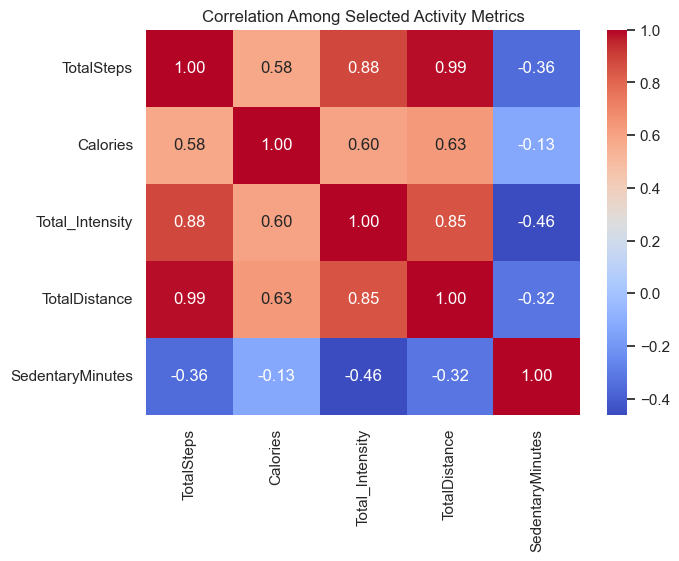

In [40]:
corr_cols = ['TotalSteps', 'Calories', 'Total_Intensity', 'TotalDistance', 'SedentaryMinutes']
plt.figure(figsize=(7,5))
sns.heatmap(df_fitbit[corr_cols].corr(), annot = True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Among Selected Activity Metrics')
plt.show()

# Wrangle the Data

In [41]:
print(df_fitbit.isna().sum())

Id                            0
ActivityDate                  0
TotalSteps                    0
TotalDistance                 0
TrackerDistance               0
LoggedActivitiesDistance      0
VeryActiveDistance            0
ModeratelyActiveDistance      0
LightActiveDistance           0
SedentaryActiveDistance       0
VeryActiveMinutes             0
FairlyActiveMinutes           0
LightlyActiveMinutes          0
SedentaryMinutes              0
Calories                      0
Sleep_Day                   963
Total_Sleep_Records         963
Total_Minutes_Asleep        963
Total_Time_In_Bed           963
date                         31
Total_Intensity              31
Average_Intensity            31
dtype: int64


In [42]:
avg_Total_Intensity = df_fitbit['Total_Intensity'].astype('float').mean(axis=0)
print("Average:", avg_Total_Intensity)

Average: 278.78241430700444


In [43]:
df_fitbit['Total_Intensity']=df_fitbit['Total_Intensity'].replace(np.nan, avg_Total_Intensity)

In [44]:
print("Average:", avg_Total_Intensity)

Average: 278.78241430700444


In [45]:
print(df_fitbit.isna().sum())

Id                            0
ActivityDate                  0
TotalSteps                    0
TotalDistance                 0
TrackerDistance               0
LoggedActivitiesDistance      0
VeryActiveDistance            0
ModeratelyActiveDistance      0
LightActiveDistance           0
SedentaryActiveDistance       0
VeryActiveMinutes             0
FairlyActiveMinutes           0
LightlyActiveMinutes          0
SedentaryMinutes              0
Calories                      0
Sleep_Day                   963
Total_Sleep_Records         963
Total_Minutes_Asleep        963
Total_Time_In_Bed           963
date                         31
Total_Intensity               0
Average_Intensity            31
dtype: int64


In [46]:
Intensity_average = df_fitbit['Average_Intensity'].astype('float').mean(axis=0)
print("Average:", Intensity_average)

Average: 0.19527236549018379


In [47]:
df_fitbit['Average_Intensity']=df_fitbit['Average_Intensity'].replace(np.nan, Intensity_average)

In [48]:
df_fitbit.describe()

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,...,LightlyActiveMinutes,SedentaryMinutes,Calories,Sleep_Day,Total_Sleep_Records,Total_Minutes_Asleep,Total_Time_In_Bed,date,Total_Intensity,Average_Intensity
count,1.373000e+03,1373,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,1373.000000,...,1373.000000,1373.000000,1373.000000,410,410.000000,410.000000,410.000000,1342,1373.000000,1373.000000
mean,4.782326e+09,2016-04-19 04:24:17.829570304,7377.375091,5.289031,5.261930,0.128591,1.413146,0.546052,3.238128,0.001733,...,188.096140,1001.346686,2294.812090,2016-04-26 11:38:55.609756160,1.119512,419.173171,458.482927,2016-04-19 09:13:40.864381440,278.782414,0.195272
min,1.503960e+09,2016-03-12 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,2016-04-12 00:00:00,1.000000,58.000000,61.000000,2016-03-12 00:00:00,0.000000,0.000000
25%,2.320127e+09,2016-04-08 00:00:00,3321.000000,2.280000,2.270000,0.000000,0.000000,0.000000,1.730000,0.000000,...,117.000000,734.000000,1820.000000,2016-04-19 00:00:00,1.000000,361.000000,403.750000,2016-04-09 00:00:00,156.000000,0.111458
50%,4.445115e+09,2016-04-19 00:00:00,7142.000000,5.030000,5.020000,0.000000,0.120000,0.200000,3.280000,0.000000,...,196.000000,1062.000000,2129.000000,2016-04-27 00:00:00,1.000000,432.500000,463.000000,2016-04-20 00:00:00,286.000000,0.200694
75%,6.962181e+09,2016-04-30 00:00:00,10645.000000,7.570000,7.570000,0.000000,1.860000,0.780000,4.710000,0.000000,...,263.000000,1246.000000,2781.000000,2016-05-04 00:00:00,1.000000,490.000000,526.000000,2016-04-30 00:00:00,395.000000,0.275000
max,8.877689e+09,2016-05-12 00:00:00,36019.000000,28.030001,28.030001,6.727057,21.920000,6.480000,12.510000,0.110000,...,720.000000,1440.000000,4900.000000,2016-05-12 00:00:00,3.000000,796.000000,961.000000,2016-05-12 00:00:00,904.000000,0.627778
std,2.381544e+09,NaN,5198.133424,3.987341,3.973439,0.695630,2.622729,0.872581,2.104300,0.007800,...,113.095058,304.168197,725.526989,NaN,0.346636,118.635918,127.455140,NaN,167.210074,0.115805


In [49]:
df_fitbit = df_fitbit.drop(columns=['date','Sleep_Day','TrackerDistance'])

In [50]:
df_fitbit['has_sleep_data'] = df_fitbit['Total_Minutes_Asleep'].notna().astype(int)

In [51]:
sleep_subset = df_fitbit[df_fitbit['has_sleep_data'] == 1]

In [52]:
df_fitbit.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1373 entries, 0 to 1372
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Id                        1373 non-null   int64         
 1   ActivityDate              1373 non-null   datetime64[ns]
 2   TotalSteps                1373 non-null   int64         
 3   TotalDistance             1373 non-null   float64       
 4   LoggedActivitiesDistance  1373 non-null   float64       
 5   VeryActiveDistance        1373 non-null   float64       
 6   ModeratelyActiveDistance  1373 non-null   float64       
 7   LightActiveDistance       1373 non-null   float64       
 8   SedentaryActiveDistance   1373 non-null   float64       
 9   VeryActiveMinutes         1373 non-null   int64         
 10  FairlyActiveMinutes       1373 non-null   int64         
 11  LightlyActiveMinutes      1373 non-null   int64         
 12  SedentaryMinutes    

In [53]:
print(df_fitbit.isna().sum())

Id                            0
ActivityDate                  0
TotalSteps                    0
TotalDistance                 0
LoggedActivitiesDistance      0
VeryActiveDistance            0
ModeratelyActiveDistance      0
LightActiveDistance           0
SedentaryActiveDistance       0
VeryActiveMinutes             0
FairlyActiveMinutes           0
LightlyActiveMinutes          0
SedentaryMinutes              0
Calories                      0
Total_Sleep_Records         963
Total_Minutes_Asleep        963
Total_Time_In_Bed           963
Total_Intensity               0
Average_Intensity             0
has_sleep_data                0
dtype: int64


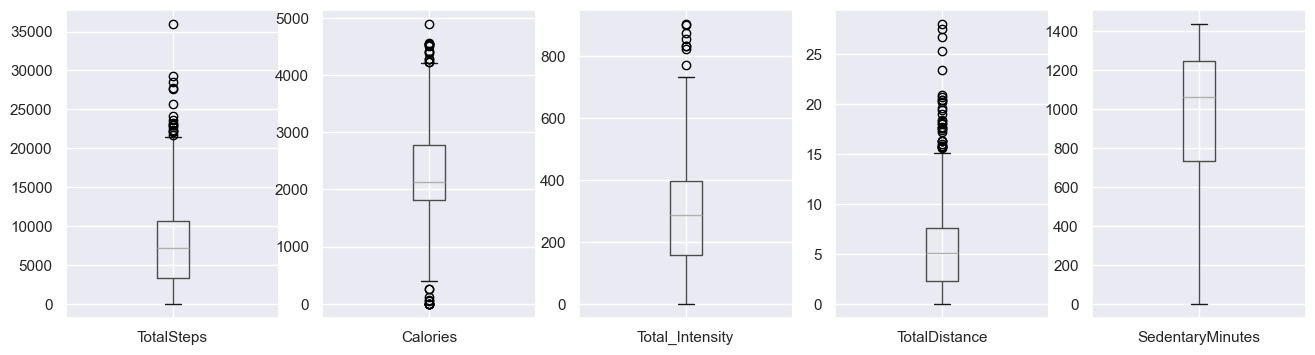

In [54]:
predictors = ['TotalSteps','Calories', 'Total_Intensity', 'TotalDistance', 'SedentaryMinutes']
fig, axes = plt.subplots(1, len(predictors), figsize=(16,4))
for ax, col in zip(axes, predictors):
    df_fitbit.boxplot(column=col, ax=ax)

In [55]:
for col in predictors:
    Q1 = df_fitbit[col].quantile(0.25)
    Q3 = df_fitbit[col].quantile(0.75)
    IQR = Q3-Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_count = ((df_fitbit[col] < lower) | (df_fitbit[col]>upper)).sum()
    print(f"{col}: {outlier_count} outliers (bounds: {lower:.1f} to {upper:.1f})")

TotalSteps: 16 outliers (bounds: -7665.0 to 21631.0)
Calories: 25 outliers (bounds: 378.5 to 4222.5)
Total_Intensity: 8 outliers (bounds: -202.5 to 753.5)
TotalDistance: 31 outliers (bounds: -5.7 to 15.5)
SedentaryMinutes: 0 outliers (bounds: -34.0 to 2014.0)


**Interpretation**
- TotalSteps: A few high outliers - represent high achievement days
- Calories: High and low outliers - represent high and low achievement days
- Total_Intensity: A few high outliers - represent high achievement days
- Total_Minutes_Asleep: More lower outliers - potential signal for recovery signal
- Sedentary Minutes - No outliers

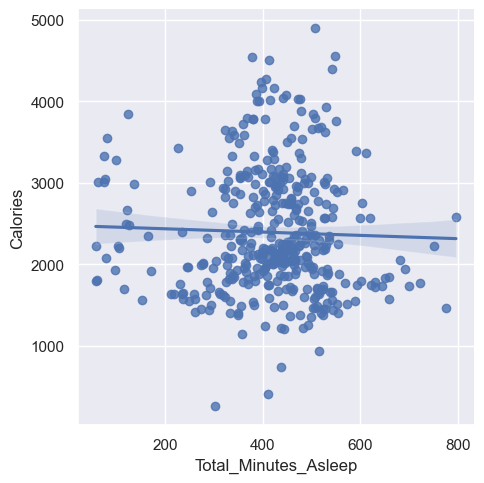

In [56]:
# Linear relationship between sleep duration and achievement score
sns.lmplot(data=df_fitbit, x='Total_Minutes_Asleep', y='Calories')
plt.show()

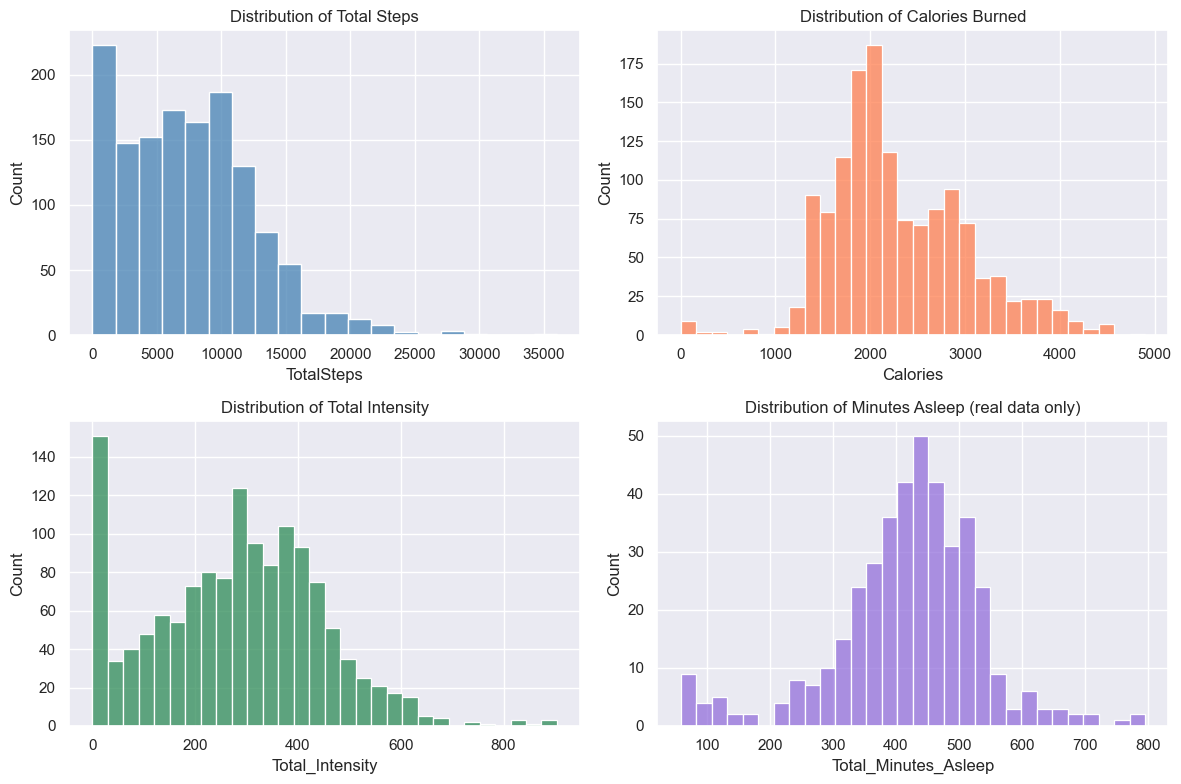

In [57]:
fig, axes = plt.subplots(2,2,figsize=(12,8))

sns.histplot(df_fitbit['TotalSteps'], bins=20, ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Distribution of Total Steps')

sns.histplot(df_fitbit['Calories'], bins=30, ax=axes[0,1], color='coral')
axes[0,1].set_title('Distribution of Calories Burned')

sns.histplot(df_fitbit['Total_Intensity'], bins=30, ax=axes[1,0], color='seagreen')
axes[1,0].set_title('Distribution of Total Intensity')

sns.histplot(df_fitbit[df_fitbit['has_sleep_data']==1]['Total_Minutes_Asleep'], bins=30, ax=axes[1,1], color='mediumpurple')
axes[1,1].set_title('Distribution of Minutes Asleep (real data only)')

plt.tight_layout()
plt.show()

## Review of Exploratory Work From Part 1

The following calorie-based relationships were originally explored during Part 1. They helped confirm that the activity variables contained meaningful information, but they are not used to evaluate the final burnout-risk classification problem.

In [58]:
df_fitbit['TotalActiveDistance'] = (
    df_fitbit['VeryActiveDistance'] +
    df_fitbit['ModeratelyActiveDistance']+
    df_fitbit['LightActiveDistance']
)
print (df_fitbit['TotalActiveDistance'].describe())

count    1373.000000
mean        5.197327
std         4.013624
min         0.000000
25%         2.090000
50%         4.940000
75%         7.510000
max        28.020000
Name: TotalActiveDistance, dtype: float64


In [59]:
df_fitbit['achievement_score'] = df_fitbit['Calories']

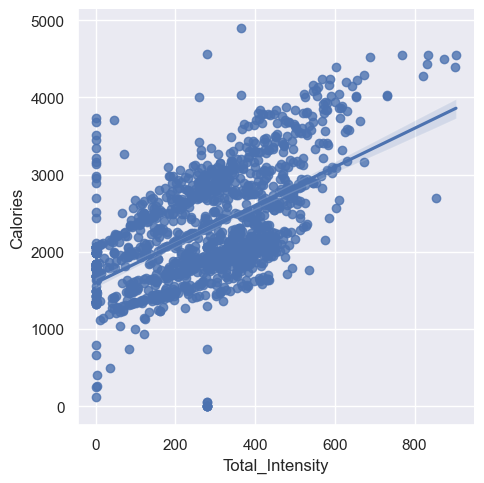

In [60]:
# Linear relationship between very active distance and achievement score
sns.lmplot(data=df_fitbit, x='Total_Intensity', y='Calories')
plt.show()

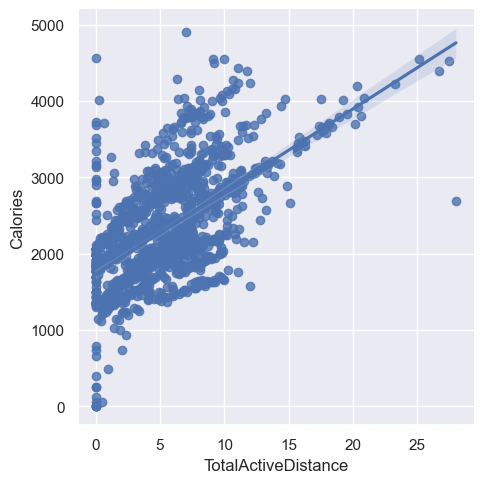

In [61]:
# Linear relationship between total active distance and achievement score
sns.lmplot(data=df_fitbit, x='TotalActiveDistance', y='Calories')
plt.show()

In [62]:
df_fitbit = df_fitbit.sort_values(['Id','ActivityDate']).reset_index(drop=True)

### Constructing a Behavioral Burnout-Risk Target

The original project proposal considered defining burnout risk as a 50% reduction in activity maintained for 14 consecutive days. After reviewing the available data, the team determined that this definition would be difficult to apply because the dataset covers a relatively short observation period.

For Part 2, the target was adjusted to identify participant-days when the participant’s seven-day rolling average of total steps falls below 70% of that participant’s average daily steps across the observed period. This represents a sustained decline of approximately 30% from the participant’s normal activity level.

The resulting target is labeled `burnout_risk`:

- `0` = no sustained activity decline
- `1` = sustained activity decline

This is a behavioral proxy and should not be interpreted as a clinical diagnosis of burnout or overtraining.

In [63]:
def per_participant_target(g): 
    participant_id = g.name
    g=g.set_index('ActivityDate').sort_index()
    g['roll_steps_7d'] = g['TotalSteps'].rolling('7D', min_periods=4).mean()
    g = g.reset_index()
    g['Id'] = participant_id
    return g

df_feat = df_fitbit.groupby('Id', group_keys=False).apply(per_participant_target)

df_feat['participant_baseline_steps'] = df_feat.groupby('Id')['TotalSteps'].transform('mean')

df_feat['burnout_risk'] = (df_feat['roll_steps_7d'] < 0.70 * df_feat['participant_baseline_steps']).astype(float)
df_feat.loc[df_feat['roll_steps_7d'].isna(),'burnout_risk'] = np.nan

print("Rows with a defined target:", df_feat['burnout_risk'].notna().sum(), "of", len(df_feat))
print(df_feat['burnout_risk'].value_counts(dropna=False))

Rows with a defined target: 1265 of 1373
burnout_risk
0.0    1110
1.0     155
NaN     108
Name: count, dtype: int64


### Engineering Leading Predictors

### Engineering Predictor Variables

The predictors are designed to use activity occurring before the day being classified. This helps reduce data leakage and makes the model more similar to a future early-warning system.

The engineered predictors are:

- `prior_avg_intensity_7d`: average daily intensity during the prior seven days
- `prior_avg_sleep_7d`: average sleep duration during the prior seven days
- `prior_sedentary_change`: change in recent sedentary time
- `prior_steps_trend`: change in recent step behavior

The sleep variable is explored separately because sleep data are missing for many participant-days. The main models use the three predictors with the most complete coverage: prior intensity, prior sedentary change, and prior steps trend.

In [64]:
def per_participant_features(g):
    participant_id = g.name
    g = g.set_index('ActivityDate').sort_index()
    
    g['prior_avg_intensity_7d'] = g['Total_Intensity'].rolling('7D', min_periods=4).mean().shift(1)

    g['prior_avg_sleep_7d'] = g['Total_Minutes_Asleep'].rolling('7D', min_periods=2).mean().shift(1)

    sed_3d = g['SedentaryMinutes'].rolling('3D', min_periods=2).mean()
    g['prior_sedentary_change'] = sed_3d.shift(1) - sed_3d.shift(4)

    steps_3d = g['TotalSteps'].rolling('3D', min_periods=2).mean()
    g['prior_steps_trend'] = steps_3d.shift(1) - steps_3d.shift(4)

    g = g.reset_index()
    g['Id'] = participant_id
    return g

df_feat = df_feat.groupby('Id', group_keys=False).apply(per_participant_features)

feature_cols = ['prior_avg_intensity_7d', 'prior_sedentary_change', 'prior_steps_trend']
print(df_feat[feature_cols + ['prior_avg_sleep_7d']].describe())

       prior_avg_intensity_7d  prior_sedentary_change  prior_steps_trend  \
count             1230.000000             1190.000000        1190.000000   
mean               282.659330                0.535574          37.102941   
std                129.212541              177.861639        3126.358232   
min                  0.000000             -771.666667      -14295.000000   
25%                193.464286              -73.000000       -1787.416667   
50%                297.000000                0.666667           0.000000   
75%                370.928571               74.250000        1805.250000   
max                626.142857              721.333333       12044.000000   

       prior_avg_sleep_7d  
count          462.000000  
mean           420.533107  
std             82.578714  
min            114.500000  
25%            388.762500  
50%            433.178571  
75%            466.357143  
max            656.000000  


# Participant-Level Train/Test Split

A participant-level split was selected instead of a random row-level split. Since each participant contributes multiple daily records, a random split could place the same individual in both the training and testing datasets. That could make model performance appear stronger because the model may recognize participant-specific patterns.

Using `GroupShuffleSplit` ensures that all records from one participant remain entirely in either the training or testing set. This provides a more realistic test of how the model may perform on participants it has not previously seen.

In [65]:
model_df = df_feat.dropna(subset=feature_cols + ['burnout_risk']).reset_index(drop=True)

X = model_df[feature_cols]
y = model_df['burnout_risk'].astype(int)
groups = model_df['Id']

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X,y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

train_ids = set(model_df.iloc[train_idx]['Id'])
test_ids = set(model_df.iloc[test_idx]['Id'])

print('Training rows:', len(X_train), '| participants:', len(train_ids))
print('Testing rows:', len(X_test),  '| participants:', len(test_ids))

print('Training class balance: \n', y_train.value_counts(normalize=True).round(3))
print('Testing class balance: \n', y_test.value_counts(normalize=True).round(3))

Training rows: 939 | participants: 28
Testing rows: 248 | participants: 7
Training class balance: 
 burnout_risk
0    0.886
1    0.114
Name: proportion, dtype: float64
Testing class balance: 
 burnout_risk
0    0.879
1    0.121
Name: proportion, dtype: float64


**Interpretation:** The 35 participants split into 28 for training and 7 for testing. The proportion of sustained decline days is similar in both sets (roughly 11-12%), meaning the split didn't concentrate the burnout days into one side.

This regression examines whether total active distance is associated with the achievement score. It is an exploratory calorie-prediction model and should not be interpreted as a burnout model.

# Baseline Model: Decision Tree Classifier

The Decision Tree is used as the baseline classification model because it is easy to interpret and can capture nonlinear relationships between the predictor variables and the activity-decline target. Class weights are balanced because sustained-decline observations represent only about 11% to 12% of the modeling data.

Accuracy: 0.8830645161290323
              precision    recall  f1-score   support

           0       0.96      0.91      0.93       218
           1       0.51      0.70      0.59        30

    accuracy                           0.88       248
   macro avg       0.73      0.80      0.76       248
weighted avg       0.90      0.88      0.89       248



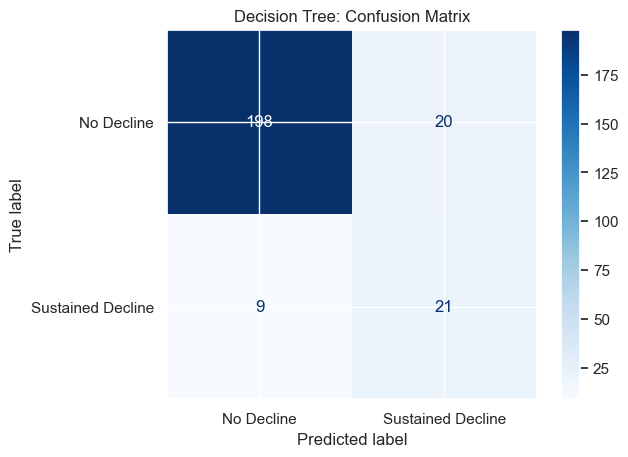

In [66]:
df_clf = DecisionTreeClassifier(max_depth=4, class_weight = 'balanced', random_state=42)
df_clf.fit(X_train, y_train)
y_pred_dt = df_clf.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt, zero_division=0))

cm = confusion_matrix(y_test, y_pred_dt, labels = [0,1])
ConfusionMatrixDisplay(cm, display_labels = ['No Decline', 'Sustained Decline']).plot(cmap='Blues')
plt.title('Decision Tree: Confusion Matrix')
plt.show()

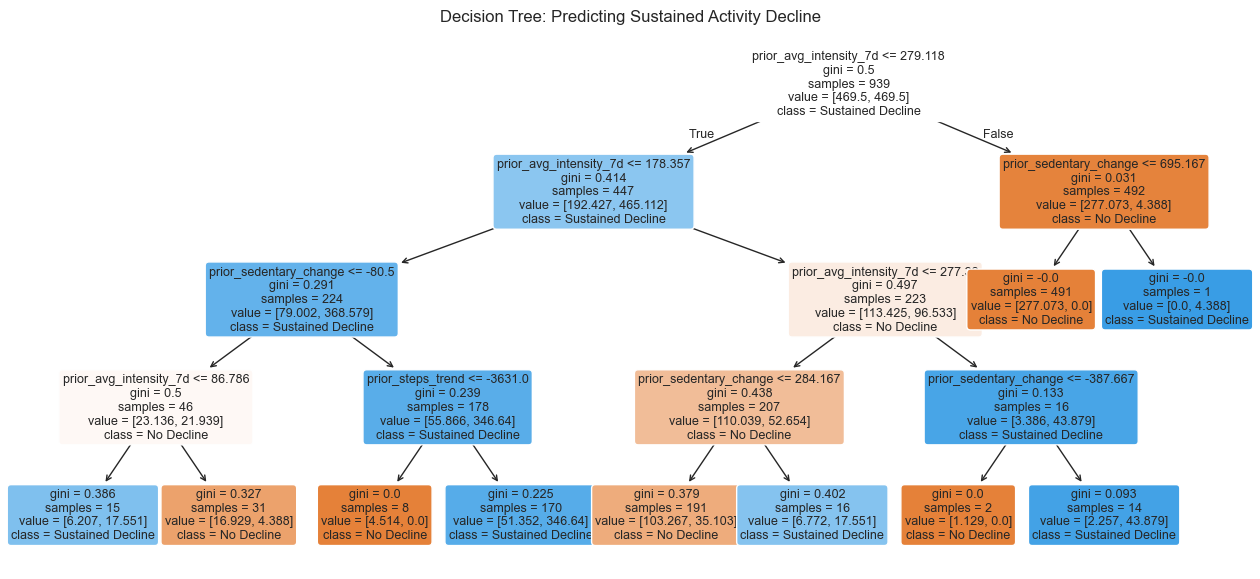

In [67]:
plt.figure(figsize=(16, 7))

plot_tree(
    df_clf,
    feature_names=feature_cols,
    class_names=['No Decline', 'Sustained Decline'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Decision Tree: Predicting Sustained Activity Decline')
plt.show()

### Decision Tree Results

The baseline Decision Tree achieved approximately 88% accuracy on the participant-level test set. For the sustained-decline class, the model achieved 51% precision and 70% recall.

The 70% recall means the model identified most of the true sustained-decline observations. The lower precision indicates that some observations predicted as sustained declines were false alarms. In the context of an early-warning system, higher recall may be preferable because missing a true decline event could be more concerning than issuing an occasional unnecessary warning.

Because the no-decline class represents most of the data, accuracy should not be used by itself. Precision, recall, F1-score, and the confusion matrix provide a more complete evaluation.

# Comparing Promising Classification Models

The baseline Decision Tree provides an interpretable starting point, but additional models should be evaluated before selecting the most promising approach.

Three classification models are compared using the same participant-level training and testing datasets:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

Logistic Regression provides a simple baseline for identifying linear relationships. The Decision Tree can capture nonlinear patterns and is easy to interpret. Random Forest combines many decision trees and may provide more stable predictions than a single tree.

Because sustained activity declines are less common than no-decline observations, balanced class weights are used where available. The models are compared using accuracy, precision, recall, and F1-score for the sustained-decline class.

In [71]:
# Define the candidate classification models
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            class_weight='balanced',
            random_state=42,
            max_iter=1000
        ))
    ]),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=4,
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42
    )
}

# Store model results
model_results = []
model_predictions = {}

# Train and evaluate each model using the same data
for model_name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    model_predictions[model_name] = predictions

    model_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        'Recall': recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        'F1 Score': f1_score(
            y_test,
            predictions,
            zero_division=0
        )
    })

# Create a comparison table
results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

results_df.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.883,0.512,0.700,0.592
1,Logistic Regression,0.855,0.440,0.733,0.550
2,Random Forest,0.915,0.800,0.400,0.533


While the Random Forest achieved the highest overall accuracy, it identified fewer sustained activity decline cases than the Decision Tree. Since the goal of this project is to detect potential declines early, the Decision Tree's stronger balance of precision, recall, and F1-score made it the most appropriate model for further tuning.

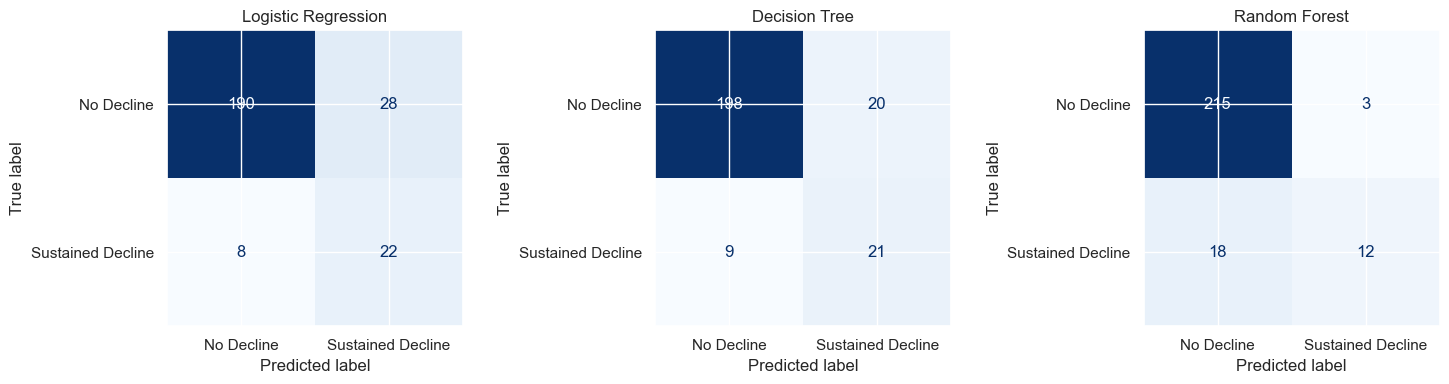

In [72]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (model_name, model) in zip(axes, models.items()):
    predictions = model_predictions[model_name]

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No Decline', 'Sustained Decline']
    ).plot(
        ax=ax,
        cmap='Blues',
        colorbar=False
    )

    ax.set_title(model_name)

plt.tight_layout()
plt.show()

The Decision Tree correctly identified more sustained activity decline cases than the Random Forest while producing fewer false negatives. Because missing a true decline is more concerning than generating an occasional false alarm, the Decision Tree remained the strongest candidate for tuning.

## Model Comparison Results

Three classification models were evaluated using the same training and testing datasets. Although the Random Forest model achieved the highest overall accuracy (91.5%), it identified only 40% of the sustained activity decline cases.

The Decision Tree produced the highest F1-score (0.592) while maintaining a good balance between precision (51.2%) and recall (70.0%). Because the goal of this project is to identify users who may begin showing sustained declines in activity, the Decision Tree provides the strongest overall performance and was selected for further tuning.

# Decision Tree Hyperparameter Tuning

The Decision Tree produced the highest F1-score during the model comparison and was selected as the most promising model for tuning.

GridSearchCV was used to test different combinations of Decision Tree settings. The parameters evaluated include maximum tree depth, the minimum number of observations required to split a node, the minimum number of observations required in a leaf, and the method used to measure split quality.

The search uses F1-score as the primary evaluation metric because the sustained-decline class is less common and both precision and recall are important.

In [75]:
# Create the Decision Tree model
tree_model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

# Define the parameter combinations to test
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy']
}

# Run grid search using F1-score
grid_search = GridSearchCV(
    estimator=tree_model,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print(
    "Best cross-validation F1-score:",
    round(grid_search.best_score_, 3)
)

Best parameters:
{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best cross-validation F1-score: 0.531


The optimal tree selected by GridSearchCV used a maximum depth of five and a minimum leaf size of ten observations. These settings reduce model complexity and help improve generalization to new data.

Tuned Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.90      0.93       218
           1       0.49      0.70      0.58        30

    accuracy                           0.88       248
   macro avg       0.72      0.80      0.75       248
weighted avg       0.90      0.88      0.88       248



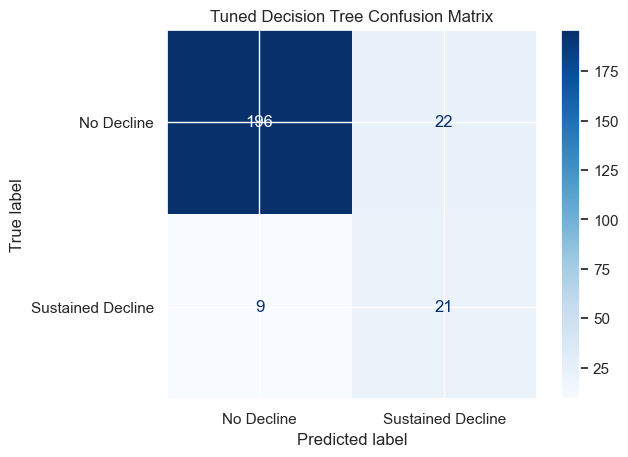

In [76]:
# Select the best Decision Tree from GridSearchCV
tuned_tree = grid_search.best_estimator_

# Make predictions on the untouched test dataset
y_pred_tuned = tuned_tree.predict(X_test)

print("Tuned Decision Tree Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_tuned,
        zero_division=0
    )
)

# Display confusion matrix
cm_tuned = confusion_matrix(
    y_test,
    y_pred_tuned,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=['No Decline', 'Sustained Decline']
).plot(cmap='Blues')

plt.title('Tuned Decision Tree Confusion Matrix')
plt.show()

In [77]:
comparison_df = pd.DataFrame({
    'Model': [
        'Original Decision Tree',
        'Tuned Decision Tree'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_tuned)
    ],
    'Precision': [
        precision_score(
            y_test,
            y_pred_dt,
            zero_division=0
        ),
        precision_score(
            y_test,
            y_pred_tuned,
            zero_division=0
        )
    ],
    'Recall': [
        recall_score(
            y_test,
            y_pred_dt,
            zero_division=0
        ),
        recall_score(
            y_test,
            y_pred_tuned,
            zero_division=0
        )
    ],
    'F1 Score': [
        f1_score(
            y_test,
            y_pred_dt,
            zero_division=0
        ),
        f1_score(
            y_test,
            y_pred_tuned,
            zero_division=0
        )
    ]
})

comparison_df.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Original Decision Tree,0.883,0.512,0.7,0.592
1,Tuned Decision Tree,0.875,0.488,0.7,0.575


## Tuning Results

GridSearchCV evaluated multiple combinations of Decision Tree hyperparameters using five-fold cross-validation and F1-score as the optimization metric.

The best-performing parameter combination was:

- Criterion: Gini
- Maximum Depth: 5
- Minimum Samples Split: 2
- Minimum Samples Leaf: 10

Although the tuned model produced a cross-validation F1-score of 0.531, its performance on the test dataset was slightly lower than the original Decision Tree.

| Model | Accuracy | Precision | Recall | F1 Score |
|-------|---------:|----------:|--------:|---------:|
| Original Decision Tree | 0.883 | 0.512 | 0.700 | 0.592 |
| Tuned Decision Tree | 0.875 | 0.488 | 0.700 | 0.575 |

The tuned model maintained the same recall but showed slightly lower accuracy, precision, and F1-score. Because the original Decision Tree achieved the strongest overall balance of evaluation metrics, it was retained as the final model for this project.

## Considering Combined Models

An ensemble model was considered after comparing the three candidate models. Since Random Forest is already an ensemble of many Decision Trees, creating an additional ensemble approach was unlikely to provide meaningful improvement for this dataset.

The original Decision Tree also remained easier to interpret while achieving the highest F1-score. Because understanding which activity measures contribute to predicting sustained activity decline is an important project objective, the original Decision Tree was selected as the final model.

# Final Model Selection

Three candidate classification models were evaluated using the same participant-level dataset.

Although Random Forest achieved the highest overall accuracy, it identified fewer sustained decline observations than the Decision Tree.

Hyperparameter tuning of the Decision Tree did not improve performance on the test dataset. As a result, the original Decision Tree was selected as the final model because it achieved the highest F1-score while maintaining good recall and providing an interpretable model.

This model will serve as the foundation for future work if additional Fitbit data or a more direct measure of workout burnout becomes available.

# Conclusion and Next Steps

This project successfully prepared the Fitbit data for machine learning, developed a participant-level classification dataset, and compared multiple classification models for predicting sustained activity decline.

Three candidate models were evaluated using common classification metrics, including accuracy, precision, recall, and F1-score. The Decision Tree provided the strongest overall balance of performance and was selected as the final model. Hyperparameter tuning was performed using GridSearchCV, but the tuned model did not outperform the original Decision Tree on the test dataset.

One limitation of this project is that the Fitbit dataset does not contain a direct measure of workout burnout. Instead, sustained activity decline was used as a proxy target variable based on changes in user activity. Future work could incorporate additional months of Fitbit data, more participants, or physiological measures such as resting heart rate or heart rate variability to improve prediction of true workout burnout.